# WICOS Project - Model 1: Logistic Regression on Hand-Crafted Features
In this notebook we classify the four radar hand gestures of the DopNet dataset (wave, pinch, swipe and click) with a multi-class (softmax) logistic regression. Logistic regression is the simplest classifier of Lecture 3, so it is the baseline for the other models. With the L1 penalty (Lasso, Lecture 2) the model also selects features: the coefficients of unimportant features become zero.

The input is `processed/wicos_dataset.npz`, created by `prepare_data.py`. Each spectrogram is described by 27 hand-crafted features: the moments of the Doppler centroid and bandwidth (Fioranelli et al., 2016), the spectrogram envelopes (Amin et al., 2019), energy statistics and the duration of the gesture.

The aim of the project is to recognise a gesture *regardless of the person who performs it*. The 40 samples per person and gesture are cut from one continuous recording, so samples of the same person are very similar. With a random split, the model sees the test person during training and the score is too optimistic.

All models are therefore validated with **leave-one-person-out (LOPO)** cross-validation: the model is trained on five persons and tested on the sixth, once for every person. Hyperparameters are chosen with a second LOPO loop *inside* the five training persons (nested cross-validation), so the test person is never used to choose the model.

In [1]:
# Import packages needed for the lab
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn import svm
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, PredefinedSplit, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

C:\Users\hawma\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.stats import gaussian_kde


In [2]:
SEED = 42
np.random.seed(SEED)

# Folders for the report figures and the results
FIG_DIR = Path("figures")
RES_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

## Task 1 - Data Preparation
- Load the prepared dataset and check the number of samples per person and gesture.

In [3]:
# Load the prepared dataset (created by prepare_data.py)
data = np.load("processed/wicos_dataset.npz", allow_pickle=True)

X = data["X_feat"]                          # hand-crafted features, not scaled yet
y = data["y"]                               # 0=wave, 1=pinch, 2=swipe, 3=click
persons = data["persons"]                   # person who performed the gesture (A-F)
feature_names = list(data["feature_names"])
gestures = list(data["gestures"])

print("Feature matrix X: " + str(X.shape))
print("Label vector y:   " + str(y.shape))

Feature matrix X: (960, 27)
Label vector y:   (960,)


In [4]:
#Number of samples per person and gesture
pd.crosstab(persons, np.array(gestures)[y], rownames=["person"], colnames=["gesture"])

gesture,click,pinch,swipe,wave
person,,,,
A,40,40,40,40
B,40,40,40,40
C,40,40,40,40
D,40,40,40,40
E,40,40,40,40
F,40,40,40,40


The features have very different units (time bins, Doppler bins, dB, ratios). They are scaled with `StandardScaler`. The scaler is part of a `Pipeline` (Lecture 6), so in every fold it is fitted on the training persons only and the test person never leaks into the scaling.

The function `lopo_scores` computes the accuracy and macro-F1 score for every held-out person. Macro-F1 averages the F1 score of the four gestures, so every gesture counts equally. `print_scores` prints the mean ± standard deviation over the six persons.

In [5]:
def lopo_scores(y_true, y_pred, groups):
    # Accuracy and macro-F1 per held-out person
    rows = []
    for p in np.unique(groups):
        mask = groups == p
        rows.append({
            "person": p,
            "accuracy": accuracy_score(y_true[mask], y_pred[mask]),
            "f1_macro": f1_score(y_true[mask], y_pred[mask], average="macro"),
        })
    return pd.DataFrame(rows)


def print_scores(scores):
    # Mean and standard deviation over the six persons
    print("Accuracy: " + f"{scores.accuracy.mean():.3f} ± {scores.accuracy.std():.3f}")
    print("F1 score (macro): " + f"{scores.f1_macro.mean():.3f} ± {scores.f1_macro.std():.3f}")

In [6]:
def clean(params):
    # Short parameter names and rounded values for printing
    return {k.split("__")[-1]: (float(f"{v:.3g}") if isinstance(v, np.floating) else v) for k, v in params.items()}

## Task 2 - Baseline model
- Develop a pipeline of `StandardScaler` and `LogisticRegression` with default parameters (L2 penalty, C = 1).
- Predict every person with a model trained on the other five persons (`cross_val_predict` with `LeaveOneGroupOut`).
- Calculate and print the accuracy and macro-F1 score.

In [7]:
#Baseline logistic regression
clf_base = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=10000)),
])

y_pred_base = cross_val_predict(clf_base, X, y, groups=persons, cv=LeaveOneGroupOut())
scores_base = lopo_scores(y, y_pred_base, persons)
print_scores(scores_base)
scores_base

Accuracy: 0.713 ± 0.156
F1 score (macro): 0.698 ± 0.178


,person,accuracy,f1_macro
0,A,0.81875,0.810139
1,B,0.41250,0.350635
2,C,0.81250,0.809176
3,D,0.75000,0.741939
4,E,0.68125,0.674230
5,F,0.80000,0.799120


## Task 3 - Hyperparameter tuning
The regularisation parameter C is the inverse of the regularisation strength λ: a small C gives a simple model (underfitting), a large C a flexible model (overfitting). We also compare the L2 (Ridge) and L1 (Lasso) penalty.

- Run a grid search over C and the penalty with LOPO cross-validation on all six persons.
- Plot the training and validation macro-F1 as a function of C for both penalties.

The scores in this task are used to *study* the hyperparameters. Because all persons are used to choose C, they are slightly optimistic; the unbiased estimate follows in Task 4.

In [8]:
#Pipeline and hyperparameter grid
clf = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(solver="saga", max_iter=10000)),
])

C_values = np.logspace(-3, 3, 13)
param_grid = {
    "clf__C": C_values,
    "clf__penalty": ["l1", "l2"],
}

#Grid search with leave-one-person-out cross-validation
search_all = GridSearchCV(clf, param_grid, cv=LeaveOneGroupOut(), scoring="f1_macro", n_jobs=-1, return_train_score=True)
search_all.fit(X, y, groups=persons)
print("Best parameters: " + str(clean(search_all.best_params_)))
print("Best validation F1 score (macro): " + str(round(search_all.best_score_, 3)))

Best parameters: {'C': 0.1, 'penalty': 'l2'}
Best validation F1 score (macro): 0.703


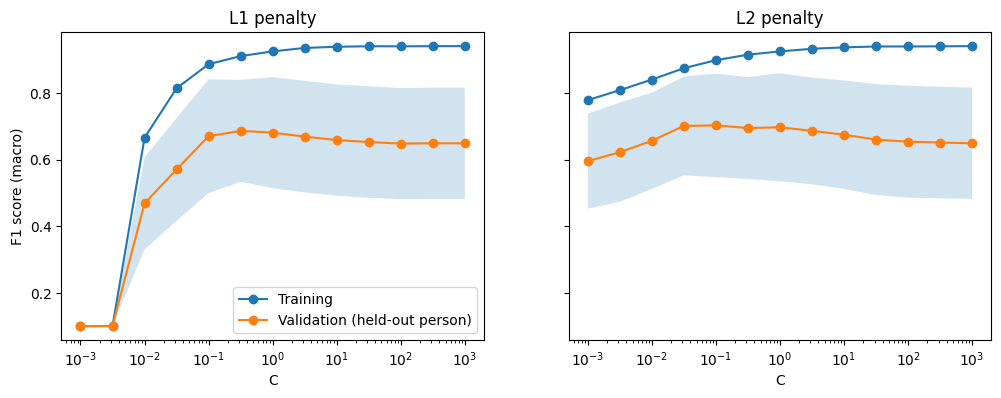

In [9]:
#Training and validation curves as a function of C
results = pd.DataFrame(search_all.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, penalty in zip(axes, ["l1", "l2"]):
    r = results[results.param_clf__penalty == penalty]
    C = r.param_clf__C.astype(float)
    ax.semilogx(C, r.mean_train_score, "o-", label="Training")
    ax.semilogx(C, r.mean_test_score, "o-", label="Validation (held-out person)")
    ax.fill_between(C, r.mean_test_score - r.std_test_score, r.mean_test_score + r.std_test_score, alpha=0.2)
    ax.set_title(f"{penalty.upper()} penalty")
    ax.set_xlabel("C")
axes[0].set_ylabel("F1 score (macro)")
axes[0].legend()
fig.savefig(FIG_DIR / "lr_validation_curve.pdf", bbox_inches="tight")
plt.show()

## Task 4 - Nested leave-one-person-out evaluation
- For every person: tune C and the penalty with a LOPO grid search on the other five persons, then test the best model once on the held-out person.
- Calculate and print the accuracy and macro-F1 score (mean ± std over the six persons).
- Plot the accuracy per person and the confusion matrix.

In [10]:
#Nested leave-one-person-out
logo = LeaveOneGroupOut()
y_pred_nested = np.zeros_like(y)
best_params = []

for train_idx, test_idx in logo.split(X, y, groups=persons):
    person = persons[test_idx][0]

    # Inner loop: tune the hyperparameters on the five training persons only
    search = GridSearchCV(clf, param_grid, cv=LeaveOneGroupOut(), scoring="f1_macro", n_jobs=-1)
    search.fit(X[train_idx], y[train_idx], groups=persons[train_idx])

    # Outer loop: test once on the held-out person
    y_pred_nested[test_idx] = search.predict(X[test_idx])
    best_params.append({"person": person, **clean(search.best_params_)})
    print(f"Person {person} held out -> best parameters: {best_params[-1]}")

scores_nested = lopo_scores(y, y_pred_nested, persons).merge(pd.DataFrame(best_params), on="person")
scores_nested

Person A held out -> best parameters: {'person': 'A', 'C': 0.316, 'penalty': 'l1'}
Person B held out -> best parameters: {'person': 'B', 'C': 0.316, 'penalty': 'l1'}
Person C held out -> best parameters: {'person': 'C', 'C': 0.316, 'penalty': 'l1'}
Person D held out -> best parameters: {'person': 'D', 'C': 0.316, 'penalty': 'l2'}
Person E held out -> best parameters: {'person': 'E', 'C': 0.1, 'penalty': 'l2'}
Person F held out -> best parameters: {'person': 'F', 'C': 1.0, 'penalty': 'l2'}


,person,accuracy,f1_macro,C,penalty
0,A,0.78750,0.788851,0.316,l1
1,B,0.43750,0.364588,0.316,l1
2,C,0.80625,0.801168,0.316,l1
3,D,0.73750,0.728068,0.316,l2
4,E,0.65625,0.647224,0.100,l2
5,F,0.80000,0.799120,1.000,l2


In [11]:
#Performance metrics
print("Baseline:")
print_scores(scores_base)
print("Tuned (nested LOPO):")
print_scores(scores_nested)

Baseline:
Accuracy: 0.713 ± 0.156
F1 score (macro): 0.698 ± 0.178
Tuned (nested LOPO):
Accuracy: 0.704 ± 0.142
F1 score (macro): 0.688 ± 0.169


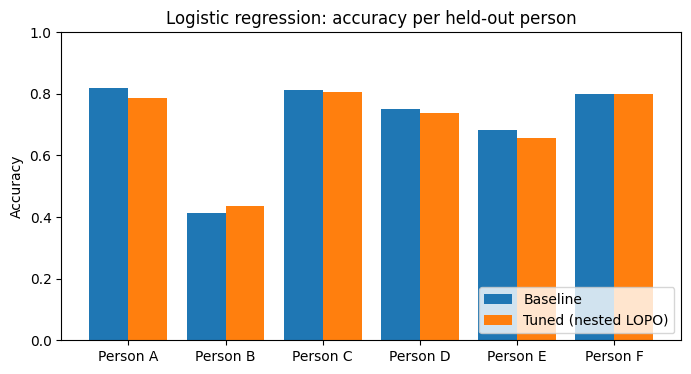

In [12]:
#Accuracy per held-out person: baseline vs tuned model
x = np.arange(len(scores_nested))

plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, scores_base.accuracy, width=0.4, label="Baseline")
plt.bar(x + 0.2, scores_nested.accuracy, width=0.4, label="Tuned (nested LOPO)")
plt.xticks(x, ["Person " + p for p in scores_nested.person])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Logistic regression: accuracy per held-out person")
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "lr_per_person.pdf", bbox_inches="tight")
plt.show()

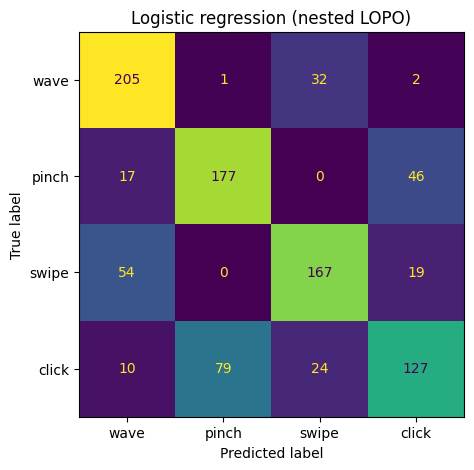

In [13]:
#Confusion matrix of the tuned model, summed over the six held-out persons
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y, y_pred_nested, display_labels=gestures, ax=ax, colorbar=False)
ax.set_title("Logistic regression (nested LOPO)")
fig.savefig(FIG_DIR / "lr_confusion_matrix.pdf", bbox_inches="tight")
plt.show()

## Task 5 - Feature selection with the L1 penalty
With the L1 penalty, the coefficients of unimportant features become exactly zero (Lecture 2). A feature is *selected* when at least one of its four class coefficients is non-zero.

- Plot the number of selected features and the validation score as a function of C.
- Train the L1 model with the best C on all data and plot its coefficients as a heat map.

The coefficients are fitted on all data only to *interpret* the model; they are not used to estimate its performance.

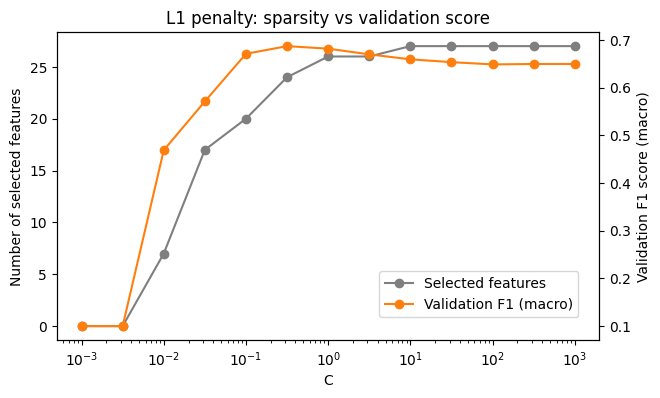

In [14]:
#Number of selected features as a function of C (L1 penalty)
n_selected = []
for C in C_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(penalty="l1", C=C, solver="saga", max_iter=10000)),
    ]).fit(X, y)
    n_selected.append(np.sum(np.any(model.named_steps["clf"].coef_ != 0, axis=0)))

r = results[results.param_clf__penalty == "l1"]

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.semilogx(C_values, n_selected, "o-", color="tab:gray", label="Selected features")
ax1.set_xlabel("C")
ax1.set_ylabel("Number of selected features")
ax2 = ax1.twinx()
ax2.semilogx(r.param_clf__C.astype(float), r.mean_test_score, "o-", color="tab:orange", label="Validation F1 (macro)")
ax2.set_ylabel("Validation F1 score (macro)")
fig.legend(loc="lower right", bbox_to_anchor=(0.88, 0.15))
ax1.set_title("L1 penalty: sparsity vs validation score")
fig.savefig(FIG_DIR / "lr_l1_selection.pdf", bbox_inches="tight")
plt.show()

Best C (L1): 0.31622776601683794
Selected features: 24 of 27
Removed features: ['env_lower_std', 'env_upper_mean', 'env_spread_mean']


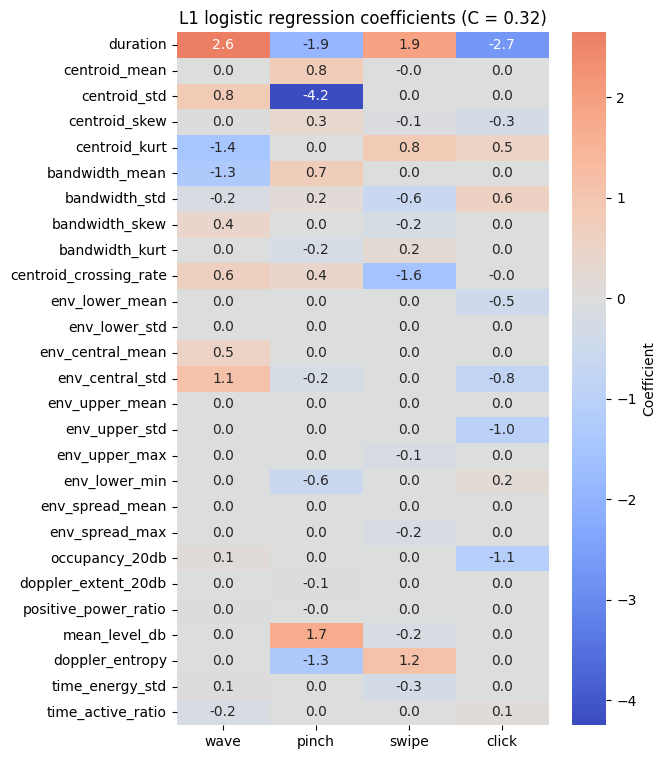

In [15]:
#L1 model with the best C for the L1 penalty
best_C_l1 = float(r.loc[r.mean_test_score.idxmax(), "param_clf__C"])
clf_l1 = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(penalty="l1", C=best_C_l1, solver="saga", max_iter=10000)),
]).fit(X, y)
coef = pd.DataFrame(clf_l1.named_steps["clf"].coef_.T, index=feature_names, columns=gestures)

selected = coef.index[(coef != 0).any(axis=1)]
print("Best C (L1): " + str(best_C_l1))
print(f"Selected features: {len(selected)} of {len(feature_names)}")
print("Removed features: " + str(list(coef.index[(coef == 0).all(axis=1)])))

#Heat map of the coefficients
plt.figure(figsize=(6, 9))
sn.heatmap(coef, annot=True, fmt=".1f", cmap="coolwarm", center=0, cbar_kws={"label": "Coefficient"})
plt.title(f"L1 logistic regression coefficients (C = {best_C_l1:.2g})")
plt.savefig(FIG_DIR / "lr_l1_coefficients.pdf", bbox_inches="tight")
plt.show()

## Task 6 - Comparison with a random split
The data exploration notebook (`wicos.ipynb`) uses a random, stratified 80/20 split. To show why we validate per person, the same model is tuned with the random 5-fold cross-validation of that notebook and tested on its random 20% test set.

- Tune the model with the predefined random folds (`cv_fold`) on the training set.
- Test it on the random test set and compare the score with the LOPO result.

In [16]:
#Random split: tune with the random 5-fold CV, test on the random 20% test set
idx_train, idx_test, cv_fold = data["idx_train"], data["idx_test"], data["cv_fold"]

search_rs = GridSearchCV(clf, param_grid, cv=PredefinedSplit(cv_fold[idx_train]), scoring="f1_macro", n_jobs=-1)
search_rs.fit(X[idx_train], y[idx_train])
y_pred_rs = search_rs.predict(X[idx_test])

accuracy_rs = accuracy_score(y[idx_test], y_pred_rs)
f1_rs = f1_score(y[idx_test], y_pred_rs, average="macro")
print("Best parameters: " + str(clean(search_rs.best_params_)))
print("Accuracy: " + str(round(accuracy_rs, 3)))
print("F1 score (macro): " + str(round(f1_rs, 3)))

Best parameters: {'C': 1.0, 'penalty': 'l2'}
Accuracy: 0.901
F1 score (macro): 0.901


In [17]:
#Random split vs leave-one-person-out
comparison = pd.DataFrame({
    "Accuracy": [accuracy_rs, scores_nested.accuracy.mean()],
    "F1 score (macro)": [f1_rs, scores_nested.f1_macro.mean()],
}, index=["Random 80/20 split", "Leave-one-person-out (mean)"])
comparison.round(3)

,Accuracy,F1 score (macro)
Random 80/20 split,0.901,0.901
Leave-one-person-out (mean),0.704,0.688


## Task 7 - Save the results
The per-person scores and a one-line summary are saved in `results/`, so all models can be compared in one table.

In [18]:
#Save the results
scores_nested.to_csv(RES_DIR / "logistic_regression_lopo.csv", index=False)

summary = pd.DataFrame([{
    "model": "Logistic regression (features)",
    "lopo_accuracy_mean": scores_nested.accuracy.mean(),
    "lopo_accuracy_std": scores_nested.accuracy.std(),
    "lopo_f1_mean": scores_nested.f1_macro.mean(),
    "lopo_f1_std": scores_nested.f1_macro.std(),
    "random_split_accuracy": accuracy_rs,
    "random_split_f1": f1_rs,
}])
summary.to_csv(RES_DIR / "logistic_regression_summary.csv", index=False)
summary.round(3)

,model,lopo_accuracy_mean,lopo_accuracy_std,lopo_f1_mean,lopo_f1_std,random_split_accuracy,random_split_f1
0,Logistic regression (features),0.704,0.142,0.688,0.169,0.901,0.901
